# Client segmentation and EDA

What the client book looks like, where churn concentrates, and which natural groups of clients exist. The goal is segments a relationship manager or marketing lead can act on, not just clusters.

Data: the latest monthly snapshot (2026-06, before the downturn), 12,000 synthetic clients.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from clientpulse.data import TARGET, generate

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
                     "axes.titlelocation": "left", "axes.titlesize": 12, "figure.dpi": 110})

try:
    df = pd.read_parquet("../data/client_snapshots.parquet")
except FileNotFoundError:
    df = generate()
snap = df[df.snapshot_month == "2026-06"].reset_index(drop=True)
print(f"{len(snap):,} clients, churn rate {snap[TARGET].mean():.1%}")

12,000 clients, churn rate 7.0%


## 1. Shape of the book

In [2]:
summary = snap.groupby("segment").agg(
    clients=("client_id", "count"),
    median_portfolio_ngn=("portfolio_value_ngn", "median"),
    total_aum_ngn=("portfolio_value_ngn", "sum"),
    churn_rate=(TARGET, "mean"),
).reindex(["retail", "affluent", "hnwi"])
summary["share_of_clients"] = summary.clients / summary.clients.sum()
summary["share_of_aum"] = summary.total_aum_ngn / summary.total_aum_ngn.sum()
summary.style.format({"median_portfolio_ngn": "N{:,.0f}", "total_aum_ngn": "N{:,.0f}",
                      "churn_rate": "{:.1%}", "share_of_clients": "{:.0%}", "share_of_aum": "{:.0%}"})

,clients,median_portfolio_ngn,total_aum_ngn,churn_rate,share_of_clients,share_of_aum
segment,,,,,,
retail,9317,"N449,300","N7,415,429,700",7.4%,78%,6%
affluent,2214,"N10,514,800","N30,307,439,300",6.1%,18%,26%
hnwi,469,"N119,775,400","N78,985,529,800",4.5%,4%,68%


A small number of high-net-worth clients hold most of the assets. Losing one HNWI costs more than losing hundreds of small retail accounts, which is why targeting by expected value matters more than targeting by churn probability.

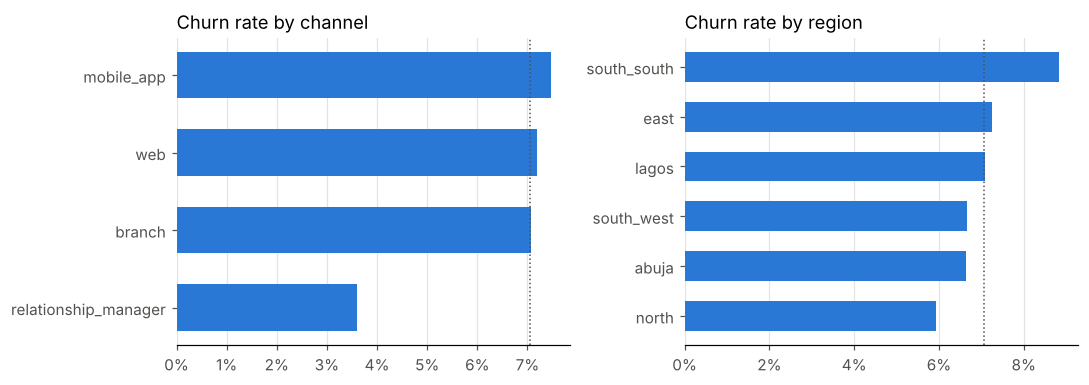

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title in [(axes[0], "channel", "Churn rate by channel"), (axes[1], "region", "Churn rate by region")]:
    r = snap.groupby(col)[TARGET].mean().sort_values()
    ax.barh(r.index, r.values, color=BLUE, height=0.6)
    ax.axvline(snap[TARGET].mean(), color=INK2, linestyle=":", linewidth=1)
    ax.set_title(title); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, 0))
fig.tight_layout()

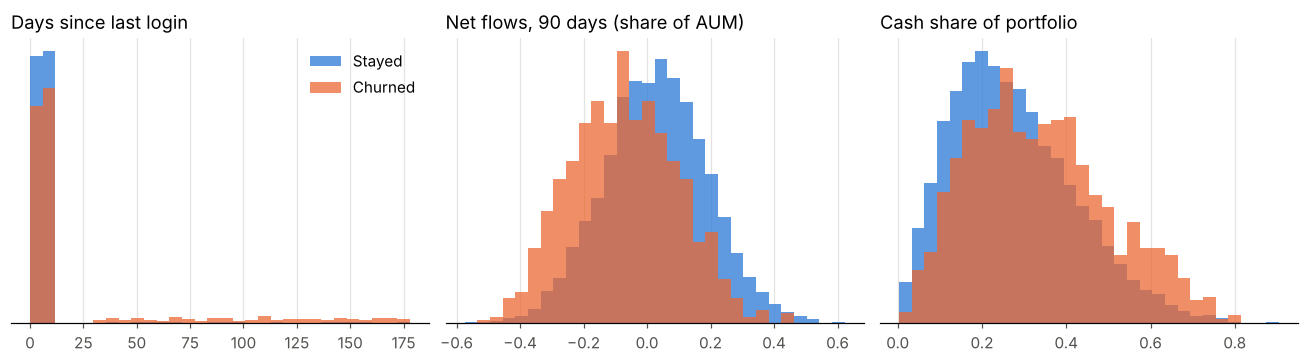

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in [(axes[0], "days_since_login", "Days since last login"),
                       (axes[1], "net_flow_90d_share", "Net flows, 90 days (share of AUM)"),
                       (axes[2], "cash_share", "Cash share of portfolio")]:
    bins = np.histogram_bin_edges(snap[col], bins=30)
    ax.hist(snap.loc[snap[TARGET] == 0, col], bins=bins, density=True, color=BLUE, alpha=0.75, label="Stayed")
    ax.hist(snap.loc[snap[TARGET] == 1, col], bins=bins, density=True, color=ORANGE, alpha=0.75, label="Churned")
    ax.set_title(title); ax.set_yticks([])
axes[0].legend(frameon=False)
fig.tight_layout()

Churners log in less, withdraw more and sit in cash. Those three signals are visible in raw data before any model, which is a good sanity check that the model's top drivers make sense.

## 2. Behavioural segmentation

K-means on behaviour, not on the demographic segment the firm already assigns. Features are scaled; portfolio value is logged so a few very large accounts do not dominate.

In [5]:
features = ["log_value", "trades_90d", "logins_30d", "days_since_login", "net_flow_90d_share",
            "cash_share", "num_asset_classes", "tenure_months"]
X = snap.assign(log_value=np.log1p(snap.portfolio_value_ngn))[features]
Xs = StandardScaler().fit_transform(X)

scores = {}
for k in range(3, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=7).fit(Xs)
    scores[k] = silhouette_score(Xs, km.labels_, sample_size=4000, random_state=7)
pd.Series(scores, name="silhouette").round(3).to_frame().T

,3,4,5,6,7
silhouette,0.128,0.206,0.136,0.142,0.149


Silhouette scores are modest at every k, which is normal for behavioural data: clients sit on a continuum rather than in tidy islands. I take the k with the best silhouette, which also keeps the number of segments small enough for the business to act on.

In [6]:
K = max(scores, key=scores.get)
print(f"chosen k = {K}")
km = KMeans(n_clusters=K, n_init=10, random_state=7).fit(Xs)
snap["cluster"] = km.labels_
profile = snap.assign(log_value=np.log1p(snap.portfolio_value_ngn)).groupby("cluster").agg(
    clients=("client_id", "count"),
    median_portfolio_ngn=("portfolio_value_ngn", "median"),
    trades_90d=("trades_90d", "mean"),
    logins_30d=("logins_30d", "mean"),
    days_since_login=("days_since_login", "mean"),
    net_flow=("net_flow_90d_share", "mean"),
    cash_share=("cash_share", "mean"),
    asset_classes=("num_asset_classes", "mean"),
    tenure=("tenure_months", "mean"),
    churn_rate=(TARGET, "mean"),
)
profile.round(2)

chosen k = 4


,clients,median_portfolio_ngn,trades_90d,logins_30d,days_since_login,net_flow,cash_share,asset_classes,tenure,churn_rate
cluster,,,,,,,,,,
0,1937,667600.0,10.65,16.09,5.42,0.15,0.25,1.58,53.93,0.03
1,7836,573500.0,3.23,5.02,5.90,-0.01,0.29,1.19,53.48,0.08
2,1967,2062000.0,5.07,7.22,5.67,0.04,0.25,3.11,52.11,0.03
3,260,783250.0,1.64,0.00,121.90,-0.08,0.33,1.28,53.70,0.45


In [7]:
# Name clusters by what stands out about each one, in order of how actionable it is
names = {}
remaining = list(profile.index)
def take(rule_name, cluster):
    names[cluster] = rule_name
    remaining.remove(cluster)

for c in profile.index[profile.days_since_login > 30]:
    take("Drifting away", c)
take("Active traders", profile.loc[remaining, "trades_90d"].idxmax())
take("Diversified investors", profile.loc[remaining, "asset_classes"].idxmax())
for i, c in enumerate(remaining):
    names[c] = "Core retail" if len(remaining) == 1 else f"Core retail {i + 1}"

profile["segment_name"] = profile.index.map(names)
snap["segment_name"] = snap.cluster.map(names)
profile.set_index("segment_name")[["clients", "median_portfolio_ngn", "trades_90d", "asset_classes",
                                   "days_since_login", "net_flow", "cash_share", "churn_rate"]].sort_values(
    "churn_rate", ascending=False).style.format(
    {"median_portfolio_ngn": "N{:,.0f}", "trades_90d": "{:.1f}", "asset_classes": "{:.1f}",
     "days_since_login": "{:.0f}", "net_flow": "{:+.0%}", "cash_share": "{:.0%}", "churn_rate": "{:.1%}"})

,clients,median_portfolio_ngn,trades_90d,asset_classes,days_since_login,net_flow,cash_share,churn_rate
segment_name,,,,,,,,
Drifting away,260,"N783,250",1.6,1.3,122,-8%,33%,45.4%
Core retail,7836,"N573,500",3.2,1.2,6,-1%,29%,7.9%
Active traders,1937,"N667,600",10.6,1.6,5,+15%,25%,3.0%
Diversified investors,1967,"N2,062,000",5.1,3.1,6,+4%,25%,2.7%


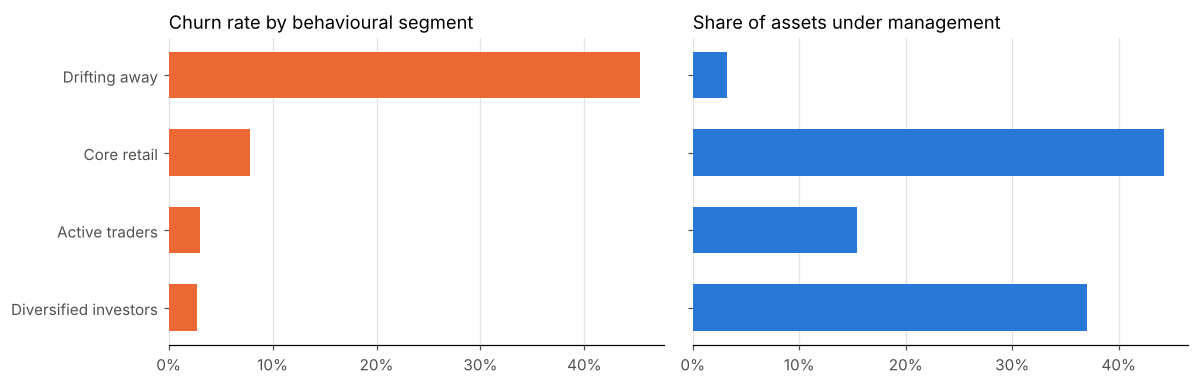

In [8]:
p = profile.set_index("segment_name").sort_values("churn_rate")
aum = snap.groupby("segment_name").portfolio_value_ngn.sum().reindex(p.index)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(p.index, p.churn_rate, color=ORANGE, height=0.6)
axes[0].set_title("Churn rate by behavioural segment")
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, 0))
axes[1].barh(p.index, aum / aum.sum(), color=BLUE, height=0.6)
axes[1].set_title("Share of assets under management")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, 0))
axes[1].set_yticklabels([])
for ax in axes: ax.grid(axis="y", visible=False)
fig.tight_layout()

## 3. What the business would do with this

| Segment | Action |
|---|---|
| Drifting away | Small group, very high churn. Re-engagement before they leave: RM call for valuable ones, app nudge for the rest. This is where the churn model's list concentrates. |
| Core retail | Most clients, mild net outflows and more cash than the rest. Offer money market or fixed income products so idle cash earns something and stays on the platform. |
| Active traders | Low churn but high commission revenue. Protect the experience: failed trades and app outages hit them hardest, so route their complaints with priority. |
| Diversified investors | Spread across asset classes and stickiest. Advisory and cross-sell; small leakage here is expensive. |

The churn model scores individuals; segments explain the population. Together they answer two different questions from the business: "who do I call this week?" and "what product or service change would move a whole group?"

**Caveats:** synthetic data, and k-means assumes roughly spherical clusters. On real data I would also try a Gaussian mixture or HDBSCAN, and check that segments stay stable month to month before anyone builds a campaign on them.